# Chapitre 1 - Cours 3 : files d'attente, débit et temps de réponse

Le cours 2 a montré que la queue de la distribution des temps de réponse est surtout faite
d'**attente**. Ce notebook explique d'où vient cette attente avec un peu de théorie des
files d'attente, que le livre évoque sans la développer : pourquoi le temps de réponse
explose quand le débit approche de la capacité, ce que dit la loi de Little, comment
une requête lente bloque celles qui la suivent, pourquoi mutualiser les serveurs aide,
et comment ne pas se tromper en mesurant sous charge. Il approfondit la section
*Describing Performance* (attentes en file et blocage en tête de file).

**Plan.**

1. La courbe en crosse de hockey : temps de réponse en fonction du débit.
2. Pourquoi on attend : hasard des arrivées et loi de Little.
3. Variabilité du service et blocage en tête de file.
4. Plusieurs serveurs : mutualiser la file et dimensionner.
5. Mesurer sous charge : boucle ouverte ou boucle fermée.


In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import requirements as rq
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 2)
rng = np.random.default_rng(0)

## 1. La courbe en crosse de hockey (section *Describing Performance*)

**Le modèle.** Un serveur à un cœur traite les requêtes une par une, dans l'ordre
d'arrivée (FIFO). Les requêtes arrivent au hasard, au rythme moyen de $\lambda$ par
seconde (processus de Poisson : instants d'arrivée indépendants) ; chacune demande un
temps de service aléatoire de moyenne $1/\mu$ (ici exponentiel, de moyenne 10 ms, soit
une capacité $\mu = 100$ requêtes par seconde). C'est la file **M/M/1** (Markov pour les
arrivées, Markov pour le service, 1 serveur). Le rapport $\rho = \lambda / \mu$ est le
**taux d'occupation** du serveur.

**Le résultat.** Le temps de réponse moyen vaut
$$W = \frac{1}{\mu - \lambda} = \frac{1/\mu}{1 - \rho},$$
et il est même distribué selon une loi exponentielle de paramètre $\mu - \lambda$, d'où
un p99 de $\ln(100)/(\mu - \lambda)$. Le facteur $1/(1-\rho)$ est la clé : à 50 %
d'occupation, on attend autant qu'on est servi ; à 90 %, le temps de réponse est
multiplié par 10 ; à 99 %, par 100. Vérifions par simulation (`rq.simulate_fifo`).

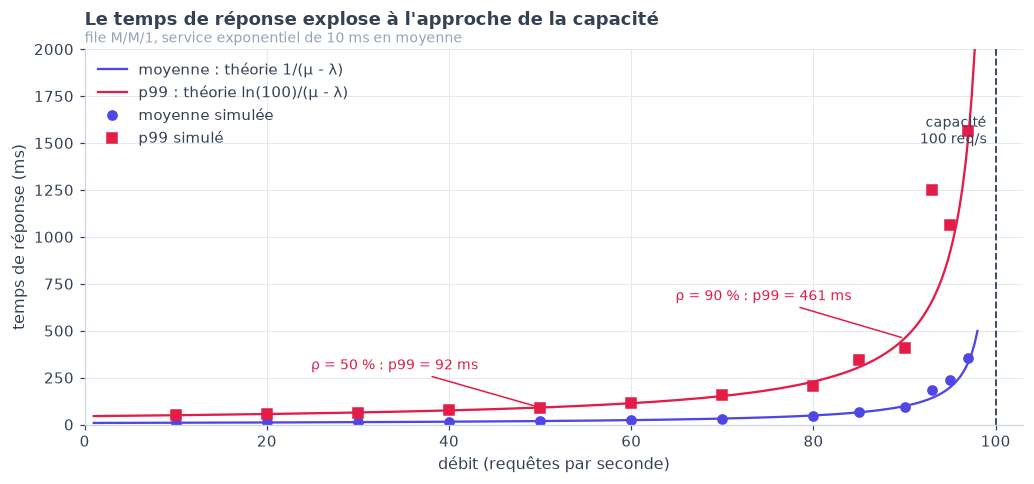

,rho,moyenne,theo_moy,p99,theo_p99
0,0.10,11.1,11.1,50.6,51.2
1,0.20,12.5,12.5,57.3,57.6
2,0.30,14.1,14.3,64.2,65.8
3,0.40,16.6,16.7,77.7,76.8
4,0.50,19.8,20.0,91.8,92.1
5,0.60,25.1,25.0,117.2,115.1
6,0.70,33.2,33.3,156.3,153.5
7,0.80,47.2,50.0,204.3,230.3
8,0.85,68.3,66.7,346.0,307.0
9,0.90,93.5,100.0,409.3,460.5


In [2]:
mu = 100.0                        # requêtes par seconde
rhos = np.array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.93, 0.95, 0.97])
rows = []
for i, rho in enumerate(rhos):
    n = 100_000
    arr = rq.poisson_arrivals(rho * mu, n, seed=i)
    svc = np.random.default_rng(100 + i).exponential(1 / mu, n)
    st, en = rq.simulate_fifo(arr, svc)
    resp = (en - arr)[n // 10:] * 1e3                     # on écarte le démarrage à vide
    rows.append(dict(rho=rho, debit=rho * mu, moyenne=resp.mean(), p99=np.percentile(resp, 99),
                     theo_moy=rq.mm1(rho * mu, mu)["W"] * 1e3,
                     theo_p99=rq.mm1_response_quantile(rho * mu, mu, 0.99) * 1e3))
M = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(9.5, 4.5))
lam = np.linspace(1, 98, 300)
ax.plot(lam, 1e3 / (mu - lam), color=INDIGO, lw=1.5, label="moyenne : théorie 1/(µ - λ)")
ax.plot(lam, math.log(100) * 1e3 / (mu - lam), color=ROSE, lw=1.5, label="p99 : théorie ln(100)/(µ - λ)")
ax.plot(M.debit, M.moyenne, "o", color=INDIGO, label="moyenne simulée")
ax.plot(M.debit, M.p99, "s", color=ROSE, label="p99 simulé")
ax.axvline(mu, color=SLATE, ls="--", lw=1.2)
ax.text(mu - 1, 1500, "capacité\n100 req/s", ha="right", color=SLATE, fontsize=9)
for r in [0.5, 0.9]:
    v = math.log(100) * 1e3 / (mu - r * mu)
    ax.annotate(f"ρ = {r * 100:.0f} % : p99 = {v:.0f} ms", (r * mu, v), (-150, 25), textcoords="offset points",
                fontsize=9, color=ROSE, arrowprops=dict(arrowstyle="-", color=ROSE))
ax.set_ylim(0, 2000); ax.set_xlim(0, 103)
ax.set_xlabel("débit (requêtes par seconde)"); ax.set_ylabel("temps de réponse (ms)")
ax.set_title("Le temps de réponse explose à l'approche de la capacité")
subtitle(ax, "file M/M/1, service exponentiel de 10 ms en moyenne")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()
M[["rho", "moyenne", "theo_moy", "p99", "theo_p99"]].round({"rho": 2, "moyenne": 1, "theo_moy": 1, "p99": 1, "theo_p99": 1})

La simulation suit la théorie, avec un peu de bruit aux fortes charges (les files très
chargées ont une forte inertie et convergent lentement). La forme en **crosse de hockey**
est universelle : quel que soit le système, le temps de réponse reste plat tant que
l'occupation est faible, puis monte en flèche. Deux conséquences pratiques :

- on ne fait pas tourner un service interactif à 95 % d'occupation : la **marge** de
  capacité est ce qui garde la queue de distribution courte ;
- à forte charge, une petite hausse du trafic (10 % de plus) peut doubler le temps de
  réponse : le système devient **fragile**.

> **À retenir.** Dans une file d'attente, le temps de réponse moyen est multiplié par
> $1/(1-\rho)$, où $\rho$ est le taux d'occupation : il explose quand le débit approche
> de la capacité. La capacité utile d'un service interactif est bien inférieure à sa
> capacité brute.